# Taller de Análisis Exploratorio de Datos (EDA)
## Caso de estudio: comercio electrónico, clientes y operación

**Nombre:** ZHARICK ZELENNY RIVERA HERNANDEZ

---

## Propósito del taller

Asumir el rol de un equipo de analítica que recibe datos reales de una empresa y debe comprenderlos antes de tomar decisiones.

No existe una única ruta de análisis ni una respuesta predeterminada. Se debe decidir qué investigar, qué variables utilizar, qué transformaciones realizar y cómo comunicar sus hallazgos.

**Regla de trabajo:** no se considera suficiente ejecutar código o producir gráficos. Cada decisión debe tener una justificación y cada resultado importante debe interpretarse en su contexto.

## Dataset seleccionado

**Brazilian E-Commerce Public Dataset by Olist**

Fuente: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

El conjunto contiene información anonimizada de aproximadamente 100.000 pedidos realizados entre 2016 y 2018. Los datos están distribuidos en archivos CSV relacionados entre sí.

### Archivos disponibles

| Archivo | Información general |
|---|---|
| `olist_orders_dataset.csv` | Pedidos, estados y fechas del proceso |
| `olist_order_items_dataset.csv` | Artículos, vendedores, precios y flete |
| `olist_customers_dataset.csv` | Identificadores y ubicación de clientes |
| `olist_products_dataset.csv` | Categorías y características de productos |
| `olist_sellers_dataset.csv` | Identificadores y ubicación de vendedores |
| `olist_order_payments_dataset.csv` | Formas y valores de pago |
| `olist_order_reviews_dataset.csv` | Calificaciones y comentarios |
| `olist_geolocation_dataset.csv` | Coordenadas asociadas a códigos postales |
| `product_category_name_translation.csv` | Traducción de categorías de productos |

**Importante:** no es obligatorio utilizar los nueve archivos. Selecciona los que necesitas para responder una pregunta de análisis. Antes de unir tablas, investiga qué representa cada fila y qué relación existe entre ellas.

# Fase 1. Comprensión del problema

## 1.1 Conocer el contexto

1. ¿Qué tipo de organización o actividad económica representa este conjunto de datos?
Una empresa de comercio electrónico que realiza ventas de productos a través de una plataforma digital y gestiona pedidos, artículos, vendedores, precios y procesos de entrega.

2. ¿Qué procesos del negocio crees que pueden estudiarse con esta información?
Se pueden estudiar las ventas, los precios de los productos, los costos, el estado de los pedidos y los tiempos de entrega.

3. ¿Qué decisiones podría tomar una empresa a partir de un análisis de estos datos?
Podría tomar decisiones relacionadas con la gestión de vendedores, control de costos de envío, seguimiento de pedidos y mejora de los tiempos de entrega.

4. ¿Qué información crees que hace falta para comprender completamente el negocio?
Sería útil contar con información sobre clientes, productos, pagos, reseñas, costos operativos, inventario y ubicación geográfica para tener una visión más completa del negocio.

## 1.2 Conectar el análisis con una perspectiva profesional

Piensa en tu formación, experiencia o área de interés.

1. ¿Qué aspecto del negocio te resulta más interesante investigar?
2. ¿Qué problema real de esa área podrías analizar con estos datos?
3. ¿Qué archivo podría contener información útil para investigarlo?
4. ¿Qué variable o indicador les gustaría comprender?
5. ¿Por qué el resultado de tu análisis sería útil para alguien que debe tomar decisiones?

**Define una perspectiva inicial de análisis:**
Analizar el comportamiento de las ventas y la eficiencia del proceso de entrega para identificar oportunidades de mejora administrativa y operativa.

In [74]:
# Escribe aquí las primeras ideas, hipótesis o preguntas que quieras investigar.


# Pregunta inicial:
# ¿Cómo se comportan las ventas y los procesos de entrega de los pedidos,
# y qué oportunidades de mejora pueden identificarse desde una perspectiva administrativa?

# Hipótesis iniciales:
# 1. La mayoría de los pedidos deberían encontrarse en estado entregado.
# 2. Los tiempos de entrega pueden variar entre los diferentes pedidos.
# 3. El valor del flete puede representar una parte importante del valor total del artículo.

# Fase 2. Selección y conocimiento de los datos

## 2.1 Selección de un único archivo

1. ¿Qué pregunta de negocio quieres responder?

¿Cómo se comportan las ventas y los procesos de entrega de los pedidos, y qué oportunidades de mejora pueden identificarse desde una perspectiva administrativa?

2. ¿Qué archivo o archivos necesitan para responderla?
3. ¿Por qué seleccionaron esos archivos y descartaron los demás?


4. ¿Qué representa una fila en cada archivo seleccionado?

En olist_orders_dataset.csv:
Cada fila representa un pedido.

En olist_order_items_dataset.csv:
Cada fila representa un artículo perteneciente a un pedido.

5. ¿Cuál podría ser la llave o identificador que permita relacionar los archivos?

En ambos aparece:  order_id
Por eso podemos relacionarlos

6. ¿Qué riesgos existen al unir tablas que tienen diferentes niveles de detalle?

**Nombre del único archivo seleccionado y justificación:**


In [75]:
# Escribe aquí el código para importar las librerías que consideres necesarias.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [76]:
# Escribe aquí el código para identificar los objetos cargados y sus dimensiones.

df_orders = pd.read_csv("olist_orders_dataset.csv")
df_items = pd.read_csv("olist_order_items_dataset.csv")
print("Pedidos:", df_orders.shape)
print("Artículos:", df_items.shape)

Pedidos: (1000, 8)
Artículos: (1380, 7)


In [77]:
with open("olist_order_items_dataset.csv","r",encoding="utf-8") as archivo:
    print(archivo.readline())
with open("olist_orders_dataset.csv","r",encoding="utf-8") as archivo:
    print(archivo.readline())

order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value

order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date



In [78]:
import os
os.listdir()

['Clase__13_Análisis_Exploratorio_De_Datos_(EDA)_Entregable.ipynb',
 'olist_orders_dataset.csv',
 'olist_orders_dataset.xlsx',
 'olist_order_items_dataset.csv',
 'olist_order_items_dataset.xlsx']

## 2.2 Reconocimiento de la estructura

Explora los datos antes de modificarlos.

1. ¿Cuántas filas y columnas tiene cada DataFrame?

Pedidos: (1000, 8)
Artículos: (1380, 7)

2. ¿Qué representa cada columna?

Pedidos (df_orders):

order_id: identificador único del pedido.
customer_id: identificador del cliente asociado al pedido.
order_status: estado actual del pedido.
order_purchase_timestamp: fecha y hora en que se realizó el pedido.
order_approved_at: fecha y hora de aprobación del pedido.
order_delivered_carrier_date: fecha en que el pedido fue entregado al transportador.
order_delivered_customer_date: fecha en que el pedido fue entregado al cliente.
order_estimated_delivery_date: fecha estimada de entrega del pedido.

Artículos (df_items):

order_id: identificador del pedido al que pertenece el artículo.
order_item_id: número o posición del artículo dentro del pedido.
product_id: identificador del producto.
seller_id: identificador del vendedor.
shipping_limit_date: fecha límite establecida para el envío del artículo.
price: precio del artículo.
freight_value: valor del flete o costo de transporte del artículo.

3. ¿Qué tipos de datos identifica Python?
En pedidos contiene variables de tipo texto(str).
Algunas variables son fechas, pero python las reconoce como texto, por lo que sera necesario realizar un cambio de formato.

En articulos contiene 4 variables de texto(str), 1 variable entera(int64) y 2 variables decimales(float64).
Las variables "price" y "freight_value" son numericas, se pueden utillizar para realizar estadisticas.

4. ¿Qué variables son numéricas, categóricas, temporales o identificadores?

En *pedidos*, order_id y customer_id son identificadores. 
order_status es una variable categórica. 
Las variables order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date y order_estimated_delivery_date son variables temporales, aunque actualmente Python las identifica como texto(str).

En artículos, order_id, product_id y seller_id son identificadores; 
order_item_id es numérica entera; 
price y freight_value son variables numéricas; y 
shipping_limit_date es una variable temporal, aunque actualmente está identificada como texto.

5. ¿Qué variables parecen relevantes para la pregunta que planteaste?

Las variables más relevantes son order_status, las diferentes fechas relacionadas con el pedido, price y freight_value. Estas variables permiten analizar el comportamiento de los pedidos, los tiempos de entrega, los valores de los artículos y los costos de transporte desde una perspectiva administrativa.

6. ¿Hay variables cuyo significado no sea evidente? ¿Cómo podrías investigarlo?

Sí. Algunas variables como order_item_id y shipping_limit_date requieren una interpretación más detallada. Para comprenderlas mejor se puede revisar el nombre de las variables, observar ejemplos de sus valores, consultar la documentación de la base de datos y comparar su comportamiento con otras variables relacionadas.

7. ¿Qué observaciones iniciales te generan curiosidad?

Resulta interesante investigar por qué algunos pedidos no tienen fecha de aprobación, de entrega al transportador o de entrega al cliente. También resulta interesante analizar la relación entre el precio de los artículos y el valor, así como estudiar cuánto tiempo tardan los pedidos en ser entregados y si existen diferencias según el estado del pedido.


**Registro de observaciones:**


In [79]:
# Escribe aquí el código necesario para inspeccionar la estructura de los datos.
print("Pedidos:", df_orders.shape)
print("Artículos:", df_items.shape)

Pedidos: (1000, 8)
Artículos: (1380, 7)


In [80]:
df_orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       1000 non-null   str  
 1   customer_id                    1000 non-null   str  
 2   order_status                   1000 non-null   str  
 3   order_purchase_timestamp       1000 non-null   str  
 4   order_approved_at              976 non-null    str  
 5   order_delivered_carrier_date   945 non-null    str  
 6   order_delivered_customer_date  899 non-null    str  
 7   order_estimated_delivery_date  1000 non-null   str  
dtypes: str(8)
memory usage: 62.6 KB


In [81]:
df_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 1380 entries, 0 to 1379
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   order_id             1380 non-null   str    
 1   order_item_id        1380 non-null   int64  
 2   product_id           1380 non-null   str    
 3   seller_id            1380 non-null   str    
 4   shipping_limit_date  1380 non-null   str    
 5   price                1380 non-null   float64
 6   freight_value        1380 non-null   float64
dtypes: float64(2), int64(1), str(4)
memory usage: 75.6 KB


In [82]:
# Escribe aquí el código para explorar registros y valores de las variables.
df_items.freight_value

0       13.67
1       21.53
2       30.74
3        6.26
4       11.16
        ...  
1375    22.38
1376    23.90
1377    14.29
1378    27.92
1379    13.82
Name: freight_value, Length: 1380, dtype: float64


# Apartado de apoyo. ¿Cómo unir tablas en Pandas?

Aunque el EDA principal se desarrolla sobre un único archivo, en un proyecto real puede ser necesario combinar información que está distribuida en varias tablas.

En Olist, por ejemplo, los pedidos y los datos de clientes se encuentran en archivos diferentes. Para analizarlos conjuntamente, se necesita identificar una columna que exista en ambas tablas y represente la misma entidad.

## Conceptos que debes comprender

- **Llave:** columna que permite relacionar registros entre tablas. Por ejemplo, `customer_id`.
- **Tabla izquierda (`left`):** DataFrame que se coloca primero en `merge`.
- **Tabla derecha (`right`):** DataFrame que se incorpora.
- **Tipo de unión (`how`):** define qué registros se conservan.

| Tipo | ¿Qué conserva? |
|---|---|
| `inner` | Solo las filas cuya llave aparece en ambas tablas. |
| `left` | Todas las filas de la tabla izquierda y las coincidencias de la derecha. |
| `right` | Todas las filas de la tabla derecha y las coincidencias de la izquierda. |
| `outer` | Todas las filas de ambas tablas; donde no hay coincidencia aparecen valores faltantes. |

## Estructura general

La función de Pandas utilizada es `merge()`:

```python
df_resultado = pd.merge(
    df_izquierdo,
    df_derecho,
    on="columna_llave",
    how="left"
)
```

Si las columnas que relacionan las tablas tienen nombres diferentes, se pueden utilizar `left_on` y `right_on`:

```python
df_resultado = pd.merge(
    df_izquierdo,
    df_derecho,
    left_on="id_tabla_1",
    right_on="id_tabla_2",
    how="inner"
)
```

## Antes de unir tablas, analiza

1. ¿Qué representa una fila en cada DataFrame?
2. ¿Cuál es la llave que relaciona las tablas?
3. ¿La llave es única en una tabla, en ambas o en ninguna?
4. ¿La relación es uno a uno, uno a muchos o muchos a muchos?
5. ¿Qué tipo de unión responde mejor a la pregunta de análisis?
6. ¿La unión puede duplicar registros? ¿Cómo lo comprobarías?
7. ¿Cuántas filas había antes y cuántas después de unir las tablas?

**Advertencia:** una unión técnicamente correcta puede producir resultados incorrectos si no se comprende el nivel de detalle de cada tabla. Por ejemplo, un pedido puede tener varios artículos; al unir pedidos con artículos, el pedido aparecerá en varias filas. Esto no necesariamente es un error: depende de qué representa cada fila en el resultado.

## Ejercicio de comprensión (no hace parte obligatoria del EDA)

Imagina que tienes una tabla de pedidos y otra de clientes.

- ¿Qué columna podría relacionarlas?
- Si quieres conservar todos los pedidos, incluso aquellos que no tengan coincidencia en la tabla de clientes, ¿qué tipo de unión elegirías?
- ¿Qué podría ocurrir si el identificador de cliente aparece varias veces en la tabla de clientes?
- ¿Qué validaciones realizarías después de la unión?

**Explica tus respuestas:**


In [83]:

# Espacio opcional para practicar merge() con dos DataFrames.
# Carga los archivos de pedidos y clientes solo si deseas realizar el ejercicio.
# Escribe aquí tu código de unión y las validaciones posteriores.


# Fase 3. Calidad y confiabilidad de los datos

Antes de analizar el comportamiento del negocio, evalúa si los datos son suficientemente confiables.

## 3.1 Diagnóstico

1. ¿Existen valores faltantes? ¿En qué variables se concentran?
En pedidos se encontraron faltantes en

En articulos no presenta valores faltantes

2. ¿Qué proporción representan los valores faltantes?
En pedidos:
order_approved_at (24), order_delivered_carrier_date (55) y order_delivered_customer_date (101).

3. ¿Existen registros duplicados? ¿Son duplicados exactos o podrían representar eventos distintos?
No se encontraron registros completamente duplicados en ninguno de los dos DataFrames. Por lo tanto, no es necesario eliminar duplicados en esta etapa

4. ¿Los tipos de datos corresponden con el significado de las variables?
Se identificó que las variables relacionadas con fechas están almacenadas como texto (str).
Las variables price y freight_value ya se encuentran correctamente identificadas como numéricas.

5. ¿Existen valores que parecen imposibles o poco razonables?
No se identificaron precios ni valores de flete negativos. Los valores observados se encuentran dentro de rangos numéricos válidos para realizar el análisis. Sin embargo, los valores máximos podrían revisarse posteriormente como posibles valores extremos.

6. ¿Hay categorías escritas de diferentes maneras que podrían representar lo mismo?
No se observan inconsistencias evidentes en los nombres de las categorías.

7. ¿Los identificadores cumplen alguna condición de unicidad?
En pedidos, order_id funciona como identificador del pedido. 
En artículos, order_id puede repetirse porque un mismo pedido puede contener varios artículos. Por esta razón, la repetición de order_id en artículos no debe considerarse un duplicado automáticamente.

8. ¿Qué otros problemas de calidad pueden afectar sus resultados?
Errores en fechas , datos incompletos, valores atipicos o inconsistencias entre pedidos y articulos

**¿Cuál de los problemas encontrados consideras más importante y por qué?**
Los valores faltantes en las fechas de entrega, porque dificultan calcular correctamente los tiempos de entrega


In [84]:
# Escribe aquí el código para investigar los valores faltantes.
print("Valores faltantes en pedidos: ")
print(df_orders.isnull().sum())

print("\nValores faltantes en articulos: ")
print(df_items.isnull().sum())

Valores faltantes en pedidos: 
order_id                           0
customer_id                        0
order_status                       0
order_purchase_timestamp           0
order_approved_at                 24
order_delivered_carrier_date      55
order_delivered_customer_date    101
order_estimated_delivery_date      0
dtype: int64

Valores faltantes en articulos: 
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64


In [85]:
# Escribe aquí el código para investigar duplicados.
print("Duplicados en pedidos:", df_orders.duplicated().sum())
print("Duplicados en artículos:", df_items.duplicated().sum())

Duplicados en pedidos: 0
Duplicados en artículos: 0


In [86]:
# Escribe aquí el código para revisar tipos de datos, categorías y posibles inconsistencias.
print("Tipos de datos de pedidos:")
print(df_orders.dtypes)

print("\nTipos de datos de artículos:")
print(df_items.dtypes)

Tipos de datos de pedidos:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Tipos de datos de artículos:
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object


In [87]:
# Escribe aquí el código para investigar los valores sospechosos que hayan identificado.
print("Precios negativos:")
print((df_items["price"] < 0).sum())

print("\nFletes negativos:")
print((df_items["freight_value"] < 0).sum())

Precios negativos:
0

Fletes negativos:
0


In [88]:
print("Precio mínimo:", df_items["price"].min())
print("Precio máximo:", df_items["price"].max())

print("Flete mínimo:", df_items["freight_value"].min())
print("Flete máximo:", df_items["freight_value"].max())

Precio mínimo: 15.0
Precio máximo: 237.19
Flete mínimo: 4.0
Flete máximo: 39.82


In [89]:
#Revicion categorias

print(df_orders["order_status"].value_counts())

order_status
delivered     899
shipped        46
canceled       31
processing     24
Name: count, dtype: int64


In [90]:
print(df_orders["order_delivered_carrier_date"].value_counts())

order_delivered_carrier_date
2017-03-02 18:23:00    1
2018-05-23 05:40:00    1
2018-03-06 16:23:00    1
2017-10-19 05:16:00    1
2017-10-15 12:04:00    1
                      ..
2018-02-13 16:03:00    1
2017-12-16 19:15:00    1
2017-08-31 10:50:00    1
2018-09-24 07:44:00    1
2017-12-02 18:44:00    1
Name: count, Length: 945, dtype: int64


In [91]:
#IDENTIFICADORES
print("Pedidos totales:", df_orders["order_id"].count())
print("Pedidos únicos:", df_orders["order_id"].nunique())

Pedidos totales: 1000
Pedidos únicos: 1000


In [92]:
print("Order_id totales en artículos:", df_items["order_id"].count())
print("Order_id únicos en artículos:", df_items["order_id"].nunique())

Order_id totales en artículos: 1380
Order_id únicos en artículos: 1000


## 3.2 Decisiones de tratamiento

No todos los problemas deben resolverse de la misma manera.

Para cada problema identificado, responde:

1. ¿Qué evidencia demuestra que existe un problema?
Valores faltantes en algunas fechas y las fechas se estan leyendo como texto (str)

2. ¿Qué alternativas de tratamiento consideran?
Convertir las fechas a (datetime), conservar los valores faltantes o eliminar registros si es necesario

3. ¿Qué información se perdería si eliminan registros?
Se perderian pedidos que pueden ser utiles para analizar las entregas

4. ¿Qué consecuencias tendría conservar los valores sin modificarlos?
No se podrian calcular correctamente los tiempos de entrega ni hacer analisis temporales

5. ¿Qué decisión tomarán y cómo justificarían esa decisión ante un equipo de negocio?
Convertir fechas y conservar los valores faltantes para asi no perder informacion valiosa, como son los pedidos


In [93]:
# Escribe aquí el código para aplicar únicamente las decisiones de limpieza que hayan justificado.

columnas_fechas_orders = ["order_purchase_timestamp",
                          "order_approved_at",
                          "order_delivered_carrier_date",
                          "order_delivered_customer_date",
                          "order_estimated_delivery_date"]

for columna in columnas_fechas_orders:
    df_orders[columna]=pd.to_datetime(df_orders[columna],errors="coerce",format="mixed",dayfirst=True)
    
print("Conversion de fechas orders realizado correctamente.")

Conversion de fechas orders realizado correctamente.


In [94]:
df_items["shipping_limit_date"]=pd.to_datetime(df_items["shipping_limit_date"],errors="coerce",format="mixed",dayfirst=True)
print("Conversion de fecha items realizado correctamente.")

Conversion de fecha items realizado correctamente.


In [95]:
# Escribe aquí el código para verificar qué cambió después del tratamiento.
print("Tipos de datos pedidos: ")
print(df_orders.dtypes)
print("\nTipos de datos de artículos:")
print(df_items.dtypes)

Tipos de datos pedidos: 
order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

Tipos de datos de artículos:
order_id                          str
order_item_id                   int64
product_id                        str
seller_id                         str
shipping_limit_date    datetime64[us]
price                         float64
freight_value                 float64
dtype: object


# Fase 4. Comprensión estadística y análisis univariado

Ahora investiguen las variables individualmente.

## 4.1 Variables numéricas

1. ¿Qué medidas estadísticas permiten comprender mejor estas variables?
Media, mediana, moda, minimo, maximo, desviacion estandar y cuartiles.

2. ¿Qué diferencias encuentran entre media, mediana y moda?
La media representa el promedio
La mediana el valor central 
La moda el valor que mas se repite

3. ¿Qué variables presentan mayor dispersión?
price presenta mayor dispercion que freight_value

4. ¿Qué tan concentrados o dispersos están sus valores?
Los valores de freight_value estan mas concentrados,
mientras que price presenta mayor variacion

5. ¿Existen observaciones extremas?
Si. se observan algunos precios superiores al valor tipico de los articulos

6. ¿Esos valores extremos son errores, casos especiales o comportamientos reales?
No necessariamente son errores, pueden corresponder a articulos de mayor valor. Se deben revisar antes de eliminar

7. ¿Qué visualización permitiría comprender mejor cada distribución?
Un histograma y diagrama de caja (boxplot)

8. ¿Qué información aporta la visualización que no sea evidente en una tabla?
Permite observar la distribucion, concentracion, dispersion y posibles valores extremos de los datos 

**Selecciona las variables que analizarán y justifiquen su elección.**


In [96]:
## Escribe aquí el código para desarrollar el análisis estadístico.

#variables numericas de interes
variables_numericas = ["price","freight_value"]
#Estadistica descriptiva
estadisticas= df_items[variables_numericas].describe()
print("Estadisticas descriptivas: ")
display(estadisticas)

#Mediana
print("\nMediana:")
print(df_items[variables_numericas].median())

# Moda
print("\nModa:")
print(df_items[variables_numericas].mode().iloc[0])

# Desviación estándar
print("\nDesviación estándar:")
print(df_items[variables_numericas].std())

Estadisticas descriptivas: 


,price,freight_value
count,1380.000000,1380.000000
mean,32.685246,18.218377
std,24.819386,7.473771
min,15.000000,4.000000
25%,15.000000,13.200000
50%,23.770000,18.105000
75%,39.742500,23.535000
max,237.190000,39.820000



Mediana:
price            23.770
freight_value    18.105
dtype: float64

Moda:
price            15.0
freight_value     4.0
Name: 0, dtype: float64

Desviación estándar:
price            24.819386
freight_value     7.473771
dtype: float64


In [97]:
import seaborn as sns

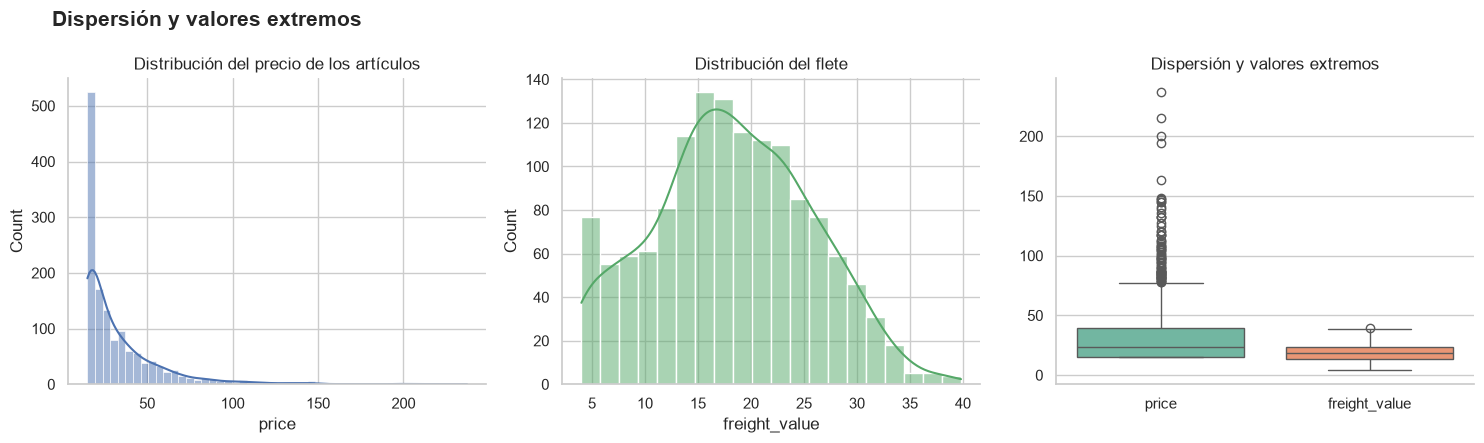

In [98]:
# Escribe aquí el código para construir las visualizaciones que consideren pertinentes.

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
fig.suptitle("Dispersión y valores extremos", fontsize=15,
             fontweight="bold", x=0.04, ha="left")

# Histograma de price
sns.histplot(data=df_items,
             x="price",
             kde=True,
             color="#4C72B0",
             ax=axes[0])

axes[0].set_title("Distribución del precio de los artículos")

# Histograma de freight_value
sns.histplot(
    data=df_items,
    x="freight_value",
    kde=True,
    color="#55A868",
    ax=axes[1]
)
axes[1].set_title("Distribución del flete")

# Boxplot
sns.boxplot(
    data=df_items[["price", "freight_value"]],
    palette="Set2",
    ax=axes[2]
)
axes[2].set_title("Dispersión y valores extremos")


sns.despine() # Elimina borde superior derecho
plt.tight_layout()
plt.show()

## 4.2 Variables categóricas

**1. ¿Cuáles son las categorías más frecuentes?**

La categoría más frecuente es “delivered”, seguida de “shipped”, “canceled” y “processing”.

**2. ¿Existen categorías poco representadas?**

Sí. Las categorías “processing” y “canceled” tienen una menor cantidad de registros en comparación con “delivered”.

**3. ¿La categoría más frecuente es necesariamente la más importante para el negocio?**

No necesariamente. Aunque “delivered” es la categoría más frecuente, “canceled” puede ser más relevante para identificar pérdidas de ventas y oportunidades de mejora.

**4. ¿Qué diferencias existen entre contar registros, pedidos, clientes y unidades?**

Un pedido puede contener varios artículos y un cliente puede realizar varios pedidos. Por eso, contar registros, pedidos, clientes y unidades representa cantidades diferentes.

**5. ¿Qué visualización facilita la comparación entre categorías?**

Un gráfico de barras facilita la comparación de la cantidad de pedidos entre las diferentes categorías.

**6. ¿Qué categorías merecen una investigación adicional?**

Las categorías “canceled” y “processing” merecen una investigación adicional para conocer las causas de los pedidos que no fueron entregados.

**¿Qué descubrimiento obtuviste al analizar las variables categóricas?**

La mayoría de los pedidos fueron entregados, mientras que una cantidad menor quedó cancelada, enviada o en procesamiento. Esto permite identificar oportunidades para analizar los pedidos que no llegaron a completarse.


Cantidad de pedidos por estado:
order_status
delivered     899
shipped        46
canceled       31
processing     24
Name: count, dtype: int64

Porcentaje de pedidos por estado:
order_status
delivered     89.9
shipped        4.6
canceled       3.1
processing     2.4
Name: proportion, dtype: float64


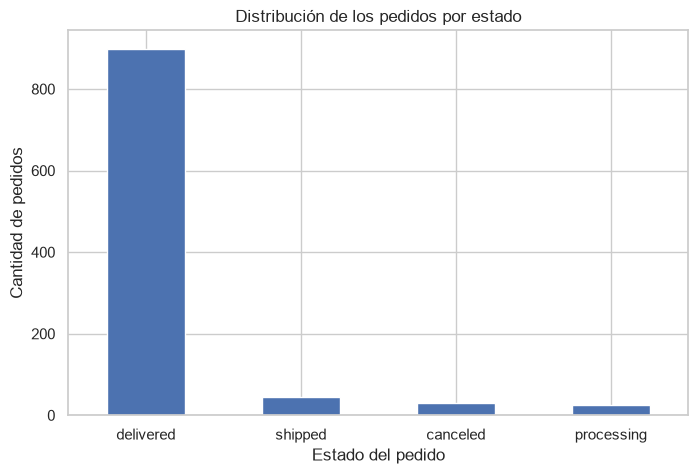

In [99]:
# Escribe aquí el código para analizar las variables categóricas y construir sus visualizaciones.

# Frecuencia de cada estado de pedido
print("Cantidad de pedidos por estado:")
print(df_orders["order_status"].value_counts())

# Porcentaje de cada estado
print("\nPorcentaje de pedidos por estado:")
print(df_orders["order_status"].value_counts(normalize=True) * 100)

# Gráfico de barras
plt.figure(figsize=(8, 5))
df_orders["order_status"].value_counts().plot(kind="bar")

plt.title("Distribución de los pedidos por estado")
plt.xlabel("Estado del pedido")
plt.ylabel("Cantidad de pedidos")
plt.xticks(rotation=0)
plt.show()

# Fase 5. Relaciones entre variables

Un análisis exploratorio no debe limitarse a describir columnas por separado. Busca relaciones que permitan comprender mejor el fenómeno.

## 5.1 Formulación de hipótesis

Plantea al menos tres hipótesis que puedan investigar con los datos seleccionados.

Para cada hipótesis:

- ¿Qué variables necesitas?
- ¿Qué relación esperas encontrar?
- ¿Por qué consideras que podría existir esa relación?
- ¿Qué resultado podría contradecir su hipótesis?

**Hipótesis 1:**
Existe una relación entre el estado del pedido y el valor de los artículos. Necesitamos las variables order_status y price. Se espera que los pedidos cancelados puedan presentar un comportamiento diferente en el valor de los artículos. La hipótesis se contradice si los valores de los artículos son similares entre todos los estados.
____________________________________________________________________

**Hipótesis 2:**
Existe una relación entre el precio del artículo y el valor del flete. Necesitamos las variables price y freight_value. Se espera que los artículos de mayor precio puedan presentar también mayores costos de flete. La hipótesis se contradice si no existe una relación clara entre ambas variables.
____________________________________________________________________

**Hipótesis 3:**
Existe una relación entre el estado del pedido y el tiempo de entrega. Necesitamos order_status y las fechas de compra y entrega. Se espera que los pedidos entregados permitan identificar diferencias en los tiempos del proceso. La hipótesis se contradice si los tiempos son similares y no muestran diferencias relevantes.
____________________________________________________________________

In [100]:
# Escribe aquí el código para investigar las hipótesis planteadas.

# Unir pedidos con artículos para poder analizar las hipótesis
df_analisis = df_items.merge(
    df_orders[
        ["order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date"]],
    on="order_id",
    how="left")

# Asegurar que las fechas estén en formato fecha
df_analisis["order_purchase_timestamp"] = pd.to_datetime(
    df_analisis["order_purchase_timestamp"],
    errors="coerce")

df_analisis["order_delivered_customer_date"] = pd.to_datetime(
    df_analisis["order_delivered_customer_date"],
    errors="coerce")

# Calcular días de entrega
df_analisis["delivery_days"] = (
    df_analisis["order_delivered_customer_date"]
    - df_analisis["order_purchase_timestamp"]).dt.days

In [101]:
# HIPÓTESIS 1: Precio promedio de los artículos según el estado del pedido
print("HIPÓTESIS 1: Precio promedio según estado del pedido")
print(df_analisis.groupby("order_status")["price"].mean().sort_values(ascending=False))

HIPÓTESIS 1: Precio promedio según estado del pedido
order_status
canceled      36.191200
delivered     32.821192
shipped       29.657231
processing    29.060000
Name: price, dtype: float64


In [102]:
# HIPÓTESIS 2: Relación entre precio y valor del flete
print("HIPÓTESIS 2: Relación entre precio y flete")
print("Correlación entre precio y flete:")
print(df_items["price"].corr(df_items["freight_value"]))

HIPÓTESIS 2: Relación entre precio y flete
Correlación entre precio y flete:
0.028094963880686323


In [103]:
# HIPÓTESIS 3: Tiempo promedio de entrega según estado del pedido
print("HIPÓTESIS 3: Tiempo promedio de entrega según estado")
print(df_analisis.groupby("order_status")["delivery_days"].mean().sort_values(ascending=False))

HIPÓTESIS 3: Tiempo promedio de entrega según estado
order_status
delivered     10.190204
canceled            NaN
processing          NaN
shipped             NaN
Name: delivery_days, dtype: float64


# Fase 6. Análisis temporal, segmentación o análisis geográfico

No todos los análisis necesitan abordar las tres perspectivas. Seleccionen las que tengan sentido para su pregunta de negocio y para las variables disponibles.

## 6.1 Análisis temporal

1. ¿Qué variables contienen fechas?
Las variables que contienen fechas son las relacionadas con la compra, aprobación y entrega de los pedidos: 
order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date y order_estimated_delivery_date.

2. ¿Qué periodos pueden analizarse?
Se puede analizar el comportamiento de los pedidos por día, mes y año. En los datos disponibles se observan pedidos entre 2017 y 2018.

3. ¿Cómo cambia el comportamiento a través del tiempo?
La cantidad de pedidos puede variar entre los diferentes meses. El análisis temporal permite identificar meses con mayor o menor actividad.

4. ¿Existen temporadas o periodos con comportamientos diferentes?
Sí. Algunos meses pueden presentar una cantidad de pedidos diferente a otros, lo que puede indicar cambios en la demanda.

5. ¿Qué eventos o condiciones podrían explicar esos cambios?
Los cambios podrían relacionarse con temporadas comerciales, promociones, fechas especiales o variaciones en la demanda.

6. ¿Qué limitaciones tiene la información temporal disponible?
Los datos no contienen información sobre promociones, campañas de marketing, días festivos o causas específicas de los cambios en las ventas, por lo que no se puede determinar con certeza el motivo de las variaciones.

**Pregunta temporal que desean investigar:**
¿Cómo cambia el comportamiento de los pedidos a través del tiempo y existen períodos con mayor o menor cantidad de pedidos?
____________________________________________________________________

In [104]:
# Escribe aquí el código para desarrollar el análisis temporal, si aplica.

# Convertir la fecha de compra a formato fecha
df_orders["order_purchase_timestamp"] = pd.to_datetime(
    df_orders["order_purchase_timestamp"],
    errors="coerce"
)

# Crear variables de año y mes
df_orders["año"] = df_orders["order_purchase_timestamp"].dt.year
df_orders["mes"] = df_orders["order_purchase_timestamp"].dt.to_period("M").astype(str)

# Cantidad de pedidos por mes
pedidos_mes = df_orders.groupby("mes").size()

print("Pedidos por mes:")
print(pedidos_mes)

Pedidos por mes:
mes
2017-01    43
2017-02    42
2017-03    58
2017-04    51
2017-05    30
2017-06    38
2017-07    55
2017-08    35
2017-09    45
2017-10    59
2017-11    45
2017-12    57
2018-01    48
2018-02    42
2018-03    43
2018-04    49
2018-05    54
2018-06    34
2018-07    34
2018-08    44
2018-09    52
2018-10    12
2018-11    13
2018-12    17
dtype: int64


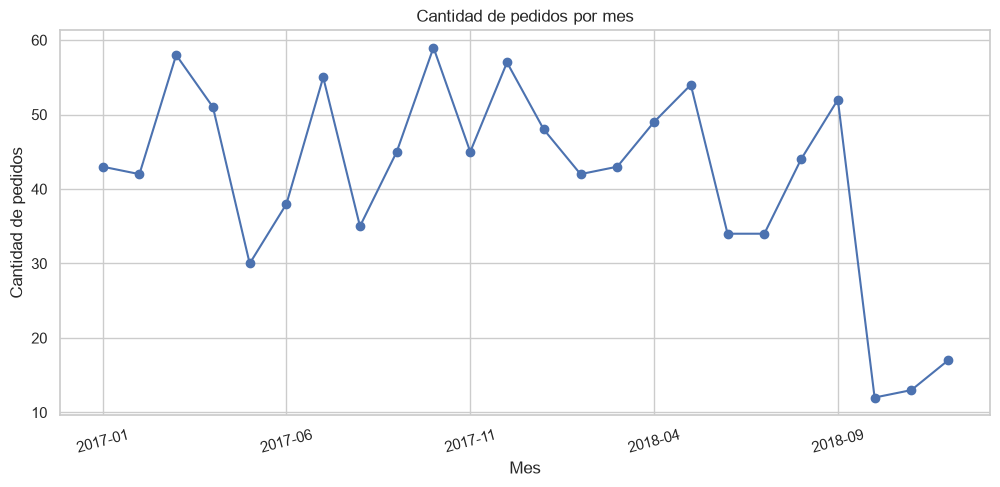

In [105]:
# Gráfico de pedidos por mes
plt.figure(figsize=(12,5))
pedidos_mes.plot(kind="line", marker="o")
plt.title("Cantidad de pedidos por mes")
plt.xlabel("Mes")
plt.ylabel("Cantidad de pedidos")
plt.xticks(rotation=15)
plt.grid(True)
plt.show()

## 6.2 Segmentación

1. ¿Qué grupos tendría sentido comparar?
Tiene sentido comparar los pedidos según su estado: entregados, enviados, procesando y cancelados.

2. ¿Qué criterio utilizarán para crear los segmentos?
El criterio de segmentación será el estado del pedido (order_status).

3. ¿Qué diferencias existen entre los grupos?
Los grupos se diferencian principalmente por la cantidad de pedidos y por su situación dentro del proceso de entrega.

4. ¿Qué segmento presenta el comportamiento más particular?
El segmento de pedidos cancelados presenta un comportamiento particular porque representa pedidos que no llegaron a completarse.

5. ¿Qué decisión podría tomarse a partir de esas diferencias?
Se recomienda hacer seguimiento a los pedidos cancelados y a los que aún no han sido entregados, con el fin de identificar oportunidades para mejorar el proceso logístico.

**Criterio de segmentación seleccionado:**
Estado del pedido (order_status)

In [106]:
# Escribe aquí el código para desarrollar la segmentación, si aplica.

# Cantidad de pedidos por segmento
segmentacion = df_orders["order_status"].value_counts()

print("Cantidad de pedidos por estado:")
print(segmentacion)

# Porcentaje de cada segmento
porcentaje = df_orders["order_status"].value_counts(normalize=True) * 100

print("\nPorcentaje de pedidos por estado:")
print(porcentaje.round(2))

Cantidad de pedidos por estado:
order_status
delivered     899
shipped        46
canceled       31
processing     24
Name: count, dtype: int64

Porcentaje de pedidos por estado:
order_status
delivered     89.9
shipped        4.6
canceled       3.1
processing     2.4
Name: proportion, dtype: float64


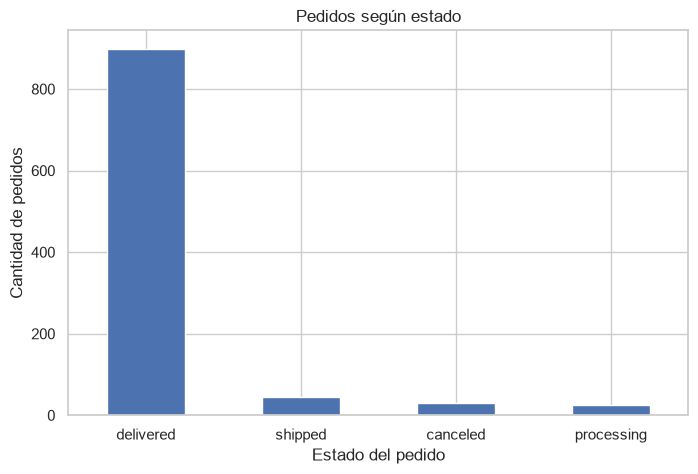

In [107]:
# Gráfico de segmentación
plt.figure(figsize=(8,5))
segmentacion.plot(kind="bar")
plt.title("Pedidos según estado")
plt.xlabel("Estado del pedido")
plt.ylabel("Cantidad de pedidos")
plt.xticks(rotation=0)
plt.show()

## 6.3 Análisis geográfico

1. ¿Qué variables permiten estudiar ubicaciones?
2. ¿Qué diferencias encuentran entre regiones?
3. ¿La ubicación parece relacionarse con alguna variable de interés?
4. ¿Qué limitaciones tiene la información geográfica?
5. ¿Qué conclusiones no sería válido afirmar con estos datos?

**Pregunta geográfica que desean investigar:**


In [108]:
# Escribe aquí el código para desarrollar el análisis geográfico, si aplica.
# Verificar las columnas disponibles para identificar información geográfica
print("Columnas de pedidos:")
print(df_orders.columns.tolist())

print("\nColumnas de artículos:")
print(df_items.columns.tolist())

Columnas de pedidos:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'año', 'mes']

Columnas de artículos:
['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']


# Fase 7. Construcción de hallazgos

En esta fase deben dejar de pensar únicamente en funciones de Python y empezar a pensar como analistas.

Selecciona entre cinco y ocho hallazgos relevantes.

Para cada hallazgo responde:

1. ¿Qué encontraste?
2. ¿Qué evidencia concreta respalda el hallazgo?
3. ¿Qué variables y operaciones utilizaste?
4. ¿Por qué es importante?
5. ¿Qué explicación posible tiene?
6. ¿Qué decisión podría tomar una organización con esta información?
7. ¿Qué tan seguros están de su interpretación?

**Hallazgo 1:**
La mayoría de los pedidos fueron entregados.
____________________________________________________________________

**Evidencia:**
De los 1.000 pedidos analizados, 899 aparecen con estado "delivered", 46 como "shipped", 31 como "canceled" y 24 como "processing".
____________________________________________________________________

**Interpretación e implicación:**
El 89,9 % de los pedidos fueron entregados, lo que indica un alto nivel de finalización del proceso. Sin embargo, los pedidos que no fueron entregados requieren seguimiento para identificar posibles problemas operativos.
____________________________________________________________________

**Hallazgo 2:**
El tiempo promedio de entrega es de aproximadamente 13,6 días.
____________________________________________________________________

**Evidencia:**
Para los 899 pedidos entregados, el promedio de entrega fue de aproximadamente 13,64 días y la mediana fue de 13,79 días.
____________________________________________________________________

**Interpretación e implicación:**
La entrega normalmente tarda alrededor de dos semanas. Esto permite establecer un indicador para evaluar el desempeño logístico.
____________________________________________________________________

**Hallazgos adicionales:**

- La base contiene 1.000 pedidos y 1.380 registros de artículos, lo que muestra que un pedido puede contener más de un artículo.
- Los datos presentan valores faltantes principalmente en algunas fechas de aprobación y entrega, por lo que estos valores deben interpretarse según el estado del pedido.
- No se realizó análisis geográfico porque los dos archivos seleccionados no contienen variables de ubicación suficientes para hacerlo.

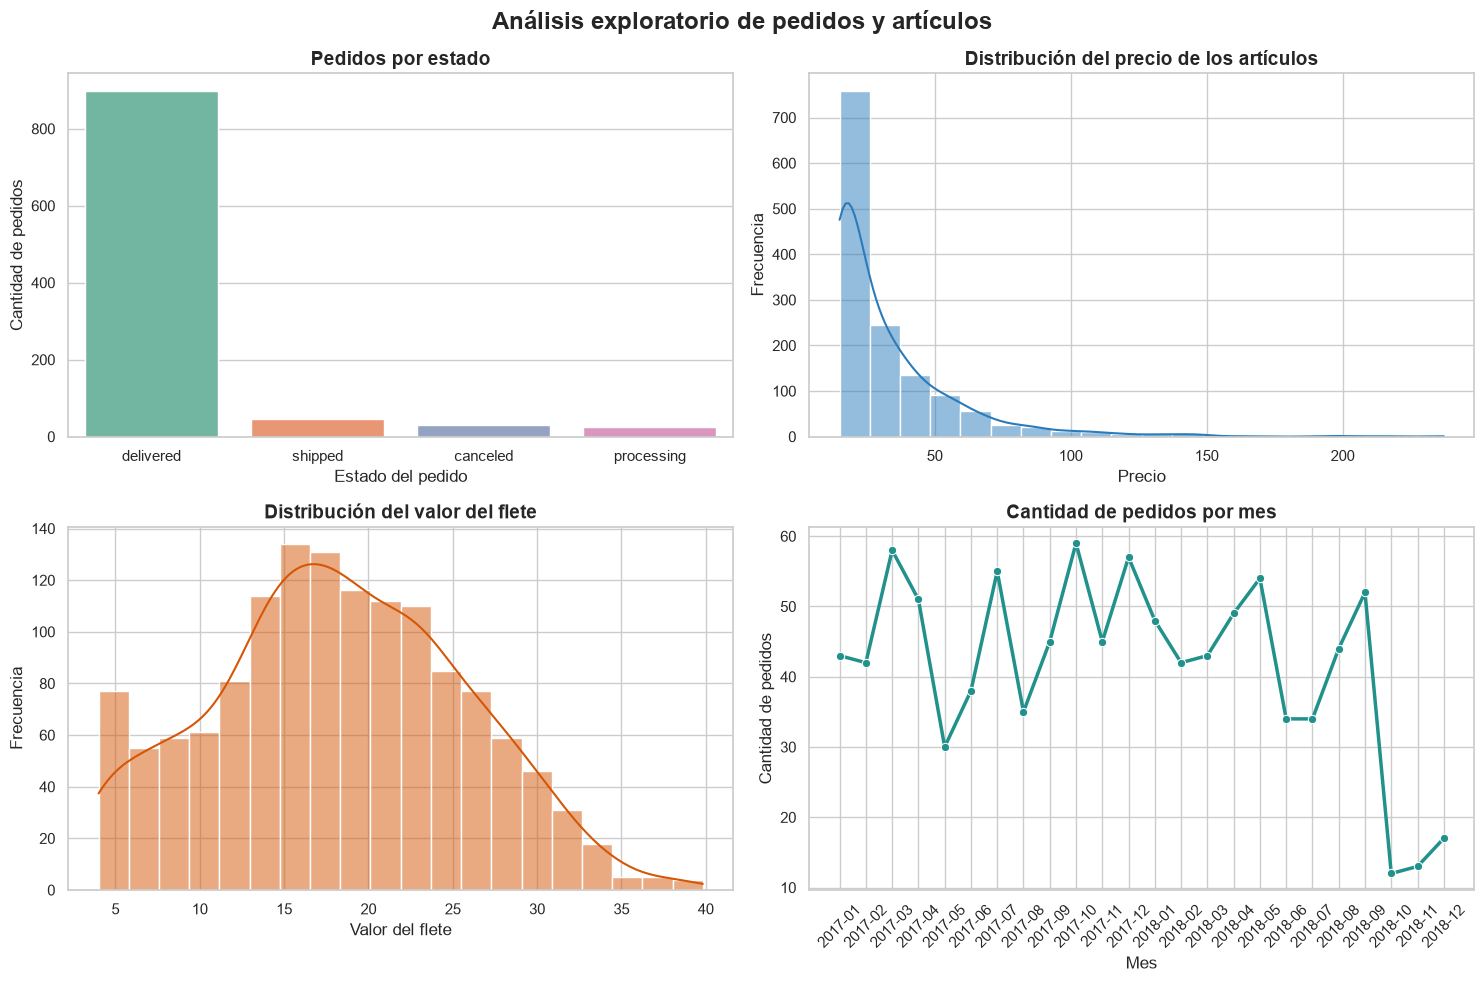

In [109]:
# Incluye aquí las tablas o visualizaciones finales que respalden tus hallazgos.
# Estilo general
sns.set_theme(style="whitegrid")


fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. PEDIDOS POR ESTADO
estado_pedidos = df_orders["order_status"].value_counts().reset_index()
estado_pedidos.columns = ["estado", "cantidad"]

sns.barplot(
    data=estado_pedidos,
    x="estado",
    y="cantidad",
    hue="estado",
    palette="Set2",
    legend=False,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Pedidos por estado", fontsize=14, fontweight="bold")
axes[0, 0].set_xlabel("Estado del pedido")
axes[0, 0].set_ylabel("Cantidad de pedidos")

# 2. DISTRIBUCIÓN DEL PRECIO
sns.histplot(
    data=df_items,
    x="price",
    bins=20,
    kde=True,
    color=sns.color_palette("Blues")[4],
    ax=axes[0, 1])

axes[0, 1].set_title("Distribución del precio de los artículos",fontsize=14, fontweight="bold")
axes[0, 1].set_xlabel("Precio")
axes[0, 1].set_ylabel("Frecuencia")

# 3. DISTRIBUCIÓN DEL FLETE
sns.histplot(
    data=df_items,
    x="freight_value",
    bins=20,
    kde=True,
    color=sns.color_palette("YlOrBr")[4],
    ax=axes[1, 0])

axes[1, 0].set_title("Distribución del valor del flete",fontsize=14, fontweight="bold")
axes[1, 0].set_xlabel("Valor del flete")
axes[1, 0].set_ylabel("Frecuencia")

# 4. PEDIDOS POR MES
df_orders["order_purchase_timestamp"] = pd.to_datetime(
    df_orders["order_purchase_timestamp"],
    errors="coerce")

pedidos_mes = (df_orders.groupby(df_orders["order_purchase_timestamp"].dt.to_period("M")).size().reset_index(name="cantidad"))

pedidos_mes["mes"] = pedidos_mes["order_purchase_timestamp"].astype(str)

sns.lineplot(
    data=pedidos_mes,
    x="mes",
    y="cantidad",
    marker="o",
    color=sns.color_palette("viridis", 5)[2],
    linewidth=2.5,
    ax=axes[1, 1])

axes[1, 1].set_title("Cantidad de pedidos por mes",fontsize=14, fontweight="bold")
axes[1, 1].set_xlabel("Mes")
axes[1, 1].set_ylabel("Cantidad de pedidos")
axes[1, 1].tick_params(axis="x", rotation=45)


plt.suptitle("Análisis exploratorio de pedidos y artículos",fontsize=17,fontweight="bold")
plt.tight_layout()
plt.show()

In [110]:
# 5. Estadísticas principales
print("Precio promedio:", round(df_items["price"].mean(), 2))
print("Flete promedio:", round(df_items["freight_value"].mean(), 2))
print("Pedidos totales:", len(df_orders))

Precio promedio: 32.69
Flete promedio: 18.22
Pedidos totales: 1000


# Fase 8. Conclusiones y recomendaciones

## 8.1 Conclusiones

1. ¿Cuál era el problema o pregunta inicial?
2. ¿Qué lograron comprender a partir de los datos?
3. ¿Qué hipótesis pudieron respaldar y cuáles no?
4. ¿Qué hallazgo consideran más importante?


**Conclusión 1:**
La pregunta inicial buscaba comprender cómo se comportan las ventas y los procesos de entrega de los pedidos, identificando posibles oportunidades de mejora desde una perspectiva administrativa.
____________________________________________________________________

**Conclusión 2:**
A partir de los datos se pudo comprender que la mayoría de los pedidos fueron entregados, con 899 de 1.000 pedidos en estado "delivered". También se identificó un tiempo promedio de entrega de aproximadamente 13,64 días y una diferencia importante entre el precio de los artículos y el valor del flete.
____________________________________________________________________

**Conclusión 3:**
Las hipótesis relacionadas con el comportamiento de las entregas, la importancia del flete y las variaciones en el tiempo pudieron ser respaldadas mediante los análisis realizados. Sin embargo, no es posible explicar con certeza las causas de las variaciones porque los datos no incluyen información sobre promociones, campañas de marketing u otros factores externos.
____________________________________________________________________

## 8.2 Recomendaciones

Formula al menos tres recomendaciones dirigidas a una persona responsable de tomar decisiones.

Cada recomendación debe estar conectada con un hallazgo y explicar qué acción se propone y qué se espera mejorar.

**Recomendación 1:**
Realizar un seguimiento periódico de los pedidos que no llegan al estado "delivered", especialmente los cancelados, enviados y en proceso. Esto permitiría identificar problemas en el proceso y reducir pedidos que no se completan.
____________________________________________________________________

**Recomendación 2:**
Revisar y negociar los costos de transporte con los proveedores logísticos, debido a que el valor promedio del flete representa una parte importante del precio de los artículos. Se espera mejorar la eficiencia de los costos y la rentabilidad de las operaciones.
____________________________________________________________________

**Recomendación 3:**
Establecer indicadores de seguimiento del tiempo de entrega, tomando como referencia el promedio de aproximadamente 13,64 días. Esto permitiría detectar retrasos, evaluar el desempeño logístico y tomar acciones para mejorar el servicio al cliente.
____________________________________________________________________
